# Time patterns
When scrobbles happen: by month, and by weekday and hour.

## Load data
Uses `scrobbles.parquet` from the project folder, or `sample_data/` if it isn't there. `played_at` is already in local time (set in the ingest notebook), so months, weekdays, and hours are local too.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import StrMethodFormatter

from viz import (BAR_COLOR, SURFACE, INK, INK_SECONDARY, MUTED, GRID, BASELINE,
                 BLUE_RAMP, add_title, save_figure)

DATA_DIR = '.' if os.path.exists('scrobbles.parquet') else 'sample_data'  # falls back to the bundled sample
print(f'data: {DATA_DIR}')

df = pd.read_parquet(f'{DATA_DIR}/scrobbles.parquet')
print(df.shape)

data: .
(33736, 5)


## Scrobbles per month
Complete months only, since the current month isn't finished yet.

In [2]:
local = df['played_at'].dt.tz_localize(None)  # drop the timezone, keep local wall-clock time
months = local.dt.to_period('M')
current_month = months.max()  # still in progress, so excluded

monthly = months[months < current_month].value_counts().sort_index()
monthly.index = monthly.index.to_timestamp()  # periods -> timestamps for plotting
monthly.tail()

played_at
2026-06-01    1204
2026-07-01    1692
2026-08-01     914
2026-09-01     576
2026-10-01     827
Freq: MS, Name: count, dtype: int64

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


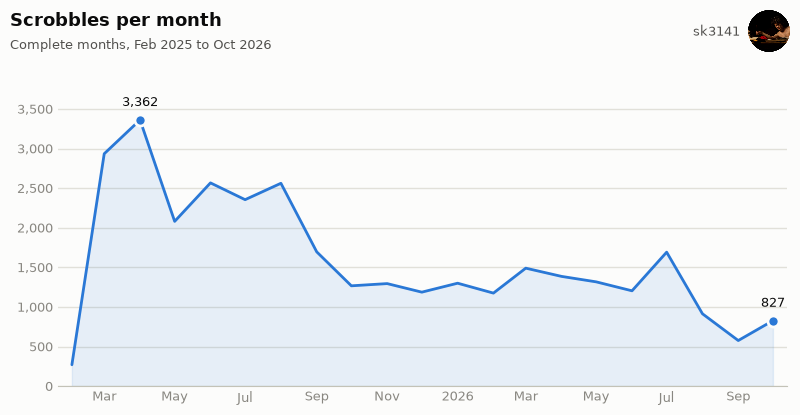

In [3]:
def plot_monthly(monthly, save=False):
    '''Line chart of scrobbles per month, with the peak and latest months labeled.'''
    height = 4.2
    fig, ax = plt.subplots(figsize=(8, height), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)

    ax.plot(monthly.index, monthly.values, color=BAR_COLOR, linewidth=2, solid_capstyle='round')
    ax.fill_between(monthly.index, monthly.values, color=BAR_COLOR, alpha=0.1)

    # label only the peak and the latest month; the axis carries the rest
    for month in {monthly.idxmax(), monthly.index[-1]}:
        value = monthly[month]
        ax.plot(month, value, 'o', markersize=8, color=BAR_COLOR,
                markeredgecolor=SURFACE, markeredgewidth=2)
        ax.annotate(f'{value:,}', (month, value), textcoords='offset points',
                    xytext=(0, 10), ha='center', fontsize=9, color=INK)

    ax.set_ylim(0, monthly.max() * 1.15)
    ax.margins(x=0.02)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    ax.yaxis.grid(True, color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(BASELINE)
    ax.tick_params(length=0, labelsize=9, labelcolor=MUTED)

    first, last = monthly.index[0], monthly.index[-1]
    add_title(fig, 'Scrobbles per month',
              f'Complete months, {first:%b %Y} to {last:%b %Y}', height)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.65 / height))
    if save:
        save_figure(fig, 'scrobbles_per_month')
    plt.show()


plot_monthly(monthly, save=True)

## Weekday and hour
Plays by weekday and hour of day. Darker cells mean more plays.

In [4]:
weekday = df['played_at'].dt.dayofweek.rename('weekday')  # 0 = Monday
hour = df['played_at'].dt.hour.rename('hour')

counts = df.groupby([weekday, hour]).size()
grid = counts.unstack(fill_value=0)  # rows = weekday, columns = hour
grid = grid.reindex(index=range(7), columns=range(24), fill_value=0)  # make sure every cell exists
grid.shape

/var/folders/ns/qrzlny7s7pj5mb7wqnwqm0k00000gn/T/ipykernel_53671/2434170007.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  weekday = df['played_at'].dt.dayofweek.rename('weekday')  # 0 = Monday


(7, 24)

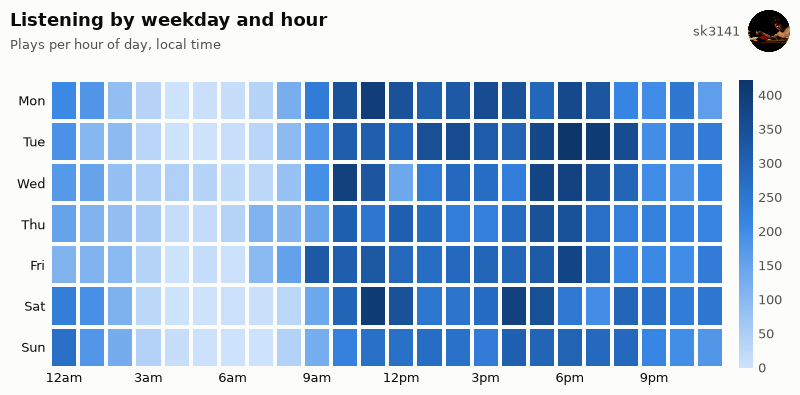

In [5]:
WEEKDAYS = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
HOUR_TICKS = [0, 3, 6, 9, 12, 15, 18, 21]
HOUR_LABELS = ['12am', '3am', '6am', '9am', '12pm', '3pm', '6pm', '9pm']


def plot_heatmap(grid, save=False):
    '''Heatmap of plays by weekday (rows) and hour of day (columns).'''
    height = 4.0
    fig, ax = plt.subplots(figsize=(8, height), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)

    cmap = LinearSegmentedColormap.from_list('blue', BLUE_RAMP)
    mesh = ax.pcolormesh(grid.values, cmap=cmap, edgecolors=SURFACE, linewidth=1.5)

    ax.set_xticks([h + 0.5 for h in HOUR_TICKS], HOUR_LABELS)
    ax.set_yticks([d + 0.5 for d in range(7)], WEEKDAYS)
    ax.invert_yaxis()  # Monday on top
    ax.tick_params(length=0, labelsize=9, labelcolor=INK)
    for spine in ax.spines.values():
        spine.set_visible(False)

    cbar = fig.colorbar(mesh, ax=ax, pad=0.02, fraction=0.04,
                        format=StrMethodFormatter('{x:,.0f}'))
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(length=0, labelsize=9, labelcolor=INK_SECONDARY)

    add_title(fig, 'Listening by weekday and hour', 'Plays per hour of day, local time', height)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.65 / height))
    if save:
        save_figure(fig, 'listening_heatmap')
    plt.show()


plot_heatmap(grid, save=True)